In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/dhoogla/nftoniot/NF-ToN-IoT.parquet


In [3]:
import pandas as pd
import plotly.graph_objects as go
import plotly.colors

# Load data
df = pd.read_parquet('/kaggle/input/datasets/dhoogla/nftoniot/NF-ToN-IoT.parquet')
df

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,63318,443,6,91.00,181,165,2,1,24,327,0,Benign
1,57442,15600,17,0.00,63,0,1,0,0,0,0,Benign
2,57452,15600,17,0.00,63,0,1,0,0,0,0,Benign
3,138,138,17,10.16,472,0,2,0,0,0,0,Benign
4,51989,15600,17,0.00,63,0,1,0,0,0,0,Benign
...,...,...,...,...,...,...,...,...,...,...,...,...
1157989,58032,80,6,7.00,216,180,4,3,18,9433,1,ddos
1157990,58034,80,6,7.00,216,180,4,3,18,9221,1,ddos
1157991,58036,80,6,7.00,216,180,4,3,18,9656,1,ddos
1157992,58038,80,6,7.00,216,180,4,3,18,10046,1,ddos


In [4]:
print("Value counts in 'label':")
print(df['Label'].value_counts())

print("\nValue counts in 'Attack':")
print(df['Attack'].value_counts())

Value counts in 'label':
Label
1    959544
0    198450
Name: count, dtype: int64

Value counts in 'Attack':
Attack
injection     460812
Benign        198450
ddos          197680
password      144792
xss            99913
scanning       20618
backdoor       17243
dos            17056
mitm            1288
ransomware       142
Name: count, dtype: int64


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1157994 entries, 0 to 1157993
Data columns (total 12 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   L4_SRC_PORT                 1157994 non-null  int32  
 1   L4_DST_PORT                 1157994 non-null  int32  
 2   PROTOCOL                    1157994 non-null  int8   
 3   L7_PROTO                    1157994 non-null  float32
 4   IN_BYTES                    1157994 non-null  int32  
 5   OUT_BYTES                   1157994 non-null  int32  
 6   IN_PKTS                     1157994 non-null  int32  
 7   OUT_PKTS                    1157994 non-null  int32  
 8   TCP_FLAGS                   1157994 non-null  int16  
 9   FLOW_DURATION_MILLISECONDS  1157994 non-null  int32  
 10  Label                       1157994 non-null  int8   
 11  Attack                      1157994 non-null  object 
dtypes: float32(1), int16(1), int32(7), int8(2), object(1)
me

In [7]:
import numpy as np

# Count NaN / null values per column
nan_counts = df.isna().sum()

print("NaN / Null values in each column:")
print(nan_counts)
print("\nTotal NaN / Null values in DataFrame:", df.isna().sum().sum())

# Count Inf / -Inf values per column
inf_counts = df.isin([np.inf, -np.inf]).sum()

print("\nInf / -Inf values in each column:")
print(inf_counts)
print("\nTotal Inf / -Inf values in DataFrame:", inf_counts.sum())

NaN / Null values in each column:
L4_SRC_PORT                   0
L4_DST_PORT                   0
PROTOCOL                      0
L7_PROTO                      0
IN_BYTES                      0
OUT_BYTES                     0
IN_PKTS                       0
OUT_PKTS                      0
TCP_FLAGS                     0
FLOW_DURATION_MILLISECONDS    0
Label                         0
Attack                        0
dtype: int64

Total NaN / Null values in DataFrame: 0

Inf / -Inf values in each column:
L4_SRC_PORT                   0
L4_DST_PORT                   0
PROTOCOL                      0
L7_PROTO                      0
IN_BYTES                      0
OUT_BYTES                     0
IN_PKTS                       0
OUT_PKTS                      0
TCP_FLAGS                     0
FLOW_DURATION_MILLISECONDS    0
Label                         0
Attack                        0
dtype: int64

Total Inf / -Inf values in DataFrame: 0


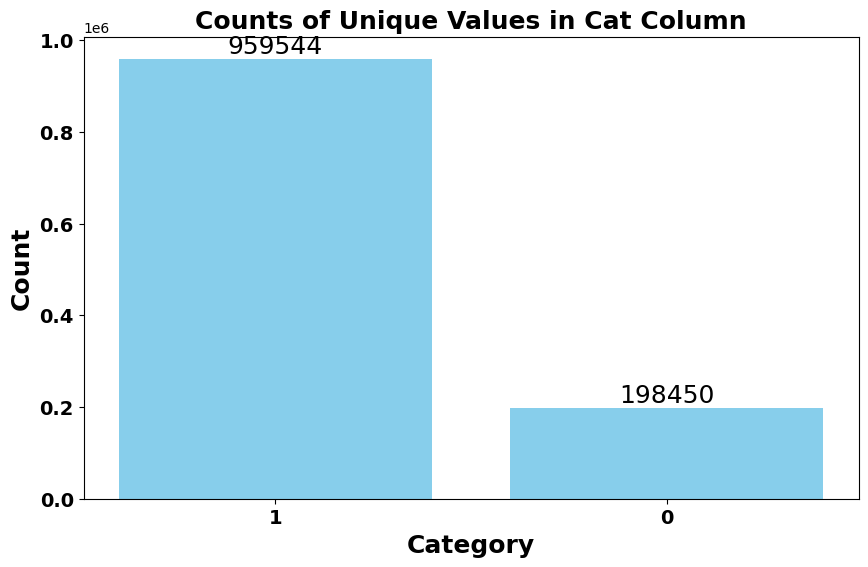

In [8]:
import matplotlib.pyplot as plt

# Get value counts
counts = df['Label'].value_counts()

# Plot
plt.figure(figsize=(10, 6))
bars = plt.bar(counts.index.astype(str), counts.values, color='skyblue')

# Add counts on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, int(yval), ha='center', va='bottom',fontsize=18)

plt.xlabel('Category',weight='bold',fontsize=18)
plt.ylabel('Count',weight='bold',fontsize=18)
plt.xticks(weight='bold',fontsize=14,rotation=0)
plt.yticks(weight='bold',fontsize=14)
plt.title('Counts of Unique Values in Cat Column',weight='bold',fontsize=18)
plt.show()


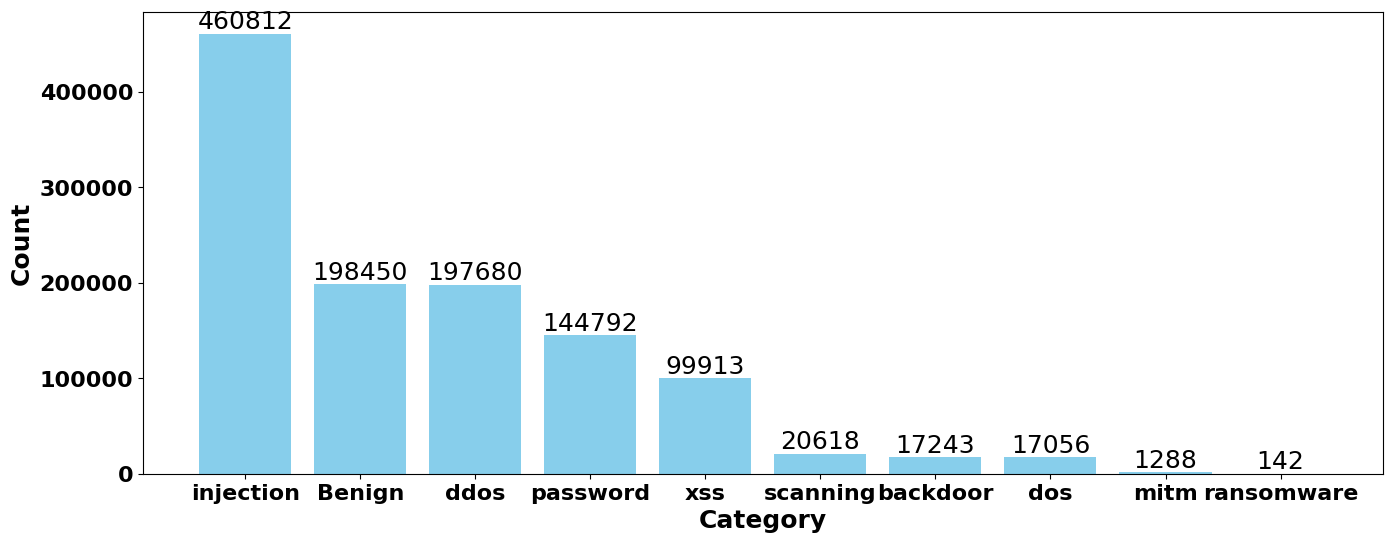

In [9]:
import matplotlib.pyplot as plt

# Get value counts
counts = df['Attack'].value_counts()

# Plot
plt.figure(figsize=(16, 6))
bars = plt.bar(counts.index, counts.values, color='skyblue')

# Add counts on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, int(yval), ha='center', va='bottom',fontsize=18)

plt.xlabel('Category',weight='bold',fontsize=18)
plt.ylabel('Count',weight='bold',fontsize=18)
plt.xticks(weight='bold',fontsize=16)
plt.yticks(weight='bold',fontsize=16)
# plt.title('Counts of Unique Values in Cat Column',weight='bold',fontsize=18)
plt.show()


In [10]:
# Define features and target
# Replace 'Label' with your target column, and drop it from features
X = df.drop(['Label', 'Attack'], axis=1).values  # Features
y = df['Label'].values                           # Target


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Standardize X values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Label encode y values
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Now split the data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

# Print shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (926395, 10)
X_test shape: (231599, 10)
y_train shape: (926395,)
y_test shape: (231599,)


In [ ]:
X = df.drop(['Label', 'Attack'], axis=1).values  # Features
y = df['Attack'].values                           # Target

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42
)

#  Now X_train, X_test, y_train, y_test exist


In [ ]:
from imblearn.over_sampling import SMOTE
import numpy as np
import pandas as pd

smote = SMOTE(
    sampling_strategy='not majority',
    k_neighbors=2,        # VERY IMPORTANT for rare classes
    random_state=42
)

X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before balancing:")
print(pd.Series(y_train).value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_bal).value_counts())


Before balancing:
4    369027
0    158659
2    158259
6    115707
9     79706
8     16507
1     13825
3     13567
5      1024
7       114
Name: count, dtype: int64

After SMOTE:
4    369027
2    369027
8    369027
0    369027
9    369027
3    369027
6    369027
1    369027
5    369027
7    369027
Name: count, dtype: int64


In [ ]:
import numpy as np
from sklearn.feature_selection import mutual_info_classif

class MultiInformationNeighborhoodSelection:
    def __init__(self, min_features=32, strategy="adaptive"):
        """
        min_features : minimum number of features to keep
        strategy     : 'adaptive' uses MI distribution automatically
        """
        self.min_features = min_features
        self.strategy = strategy
        self.selected_features_ = None
        self.mi_scores_ = None
        self.num_features_ = None

    def fit(self, X, y):
        # Compute Mutual Information
        mi = mutual_info_classif(X, y, random_state=42)
        self.mi_scores_ = mi

        # Sort features by MI (descending)
        sorted_idx = np.argsort(mi)[::-1]

        if self.strategy == "adaptive":
            # Automatic threshold based on MI distribution
            thresh = np.percentile(mi, 50)   # median-based cutoff
            auto_selected = np.where(mi >= thresh)[0]

            # Guarantee minimum number of features
            if len(auto_selected) < self.min_features:
                self.selected_features_ = sorted_idx[:self.min_features]
            else:
                self.selected_features_ = auto_selected
        else:
            raise ValueError("Invalid strategy")

        self.num_features_ = len(self.selected_features_)
        return self

    def transform(self, X):
        return X[:, self.selected_features_]

    def fit_transform(self, X, y):
        self.fit(X, y)
        return self.transform(X)



mins = MultiInformationNeighborhoodSelection(min_features=32)

X_train_sel = mins.fit_transform(X_train, y_train)
X_test_sel  = mins.transform(X_test)




In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LayerNormalization,
    GlobalAveragePooling1D, Conv1D, GRU, Concatenate
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt



X_train_gat = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_gat  = X_test.reshape(X_test.shape[0],  X_test.shape[1], 1)

num_classes = len(np.unique(y_train))



def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_true = tf.one_hot(y_true, depth=num_classes)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        ce = -y_true * tf.math.log(y_pred)
        weight = alpha * tf.pow(1 - y_pred, gamma)
        return tf.reduce_mean(weight * ce)
    return loss


class GraphAttention(tf.keras.layers.Layer):
    def __init__(self, out_dim):
        super().__init__()
        self.out_dim = out_dim

    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], self.out_dim),
                                 initializer="glorot_uniform",
                                 trainable=True)
        self.a = self.add_weight(shape=(self.out_dim, 1),
                                 initializer="glorot_uniform",
                                 trainable=True)

    def call(self, X):
        h = tf.matmul(X, self.W)
        e = tf.matmul(h, self.a)
        alpha = tf.nn.softmax(e, axis=1)
        return h * alpha


# HYBRID GAT–CNN–GRU MODEL
inputs = Input(shape=(X_train_gat.shape[1], 1))

# ---- GAT BRANCH
gat = GraphAttention(64)(inputs)
gat = LayerNormalization()(gat)
gat = Dropout(0.3)(gat)

gat = GraphAttention(128)(gat)
gat = LayerNormalization()(gat)
gat = GlobalAveragePooling1D()(gat)

# ---- CNN BRANCH ----
cnn = Conv1D(64, kernel_size=3, padding="same", activation="relu")(inputs)
cnn = Conv1D(128, kernel_size=3, padding="same", activation="relu")(cnn)
cnn = GlobalAveragePooling1D()(cnn)

# ---- GRU BRANCH ---
gru = GRU(128, return_sequences=False)(inputs)

# ---- FEATURE FUSION --
fusion = Concatenate()([gat, cnn, gru])
fusion = Dense(256, activation="relu")(fusion)
fusion = Dropout(0.5)(fusion)

outputs = Dense(num_classes, activation="softmax")(fusion)

model = Model(inputs, outputs)


# COMPILE
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=focal_loss(),
    metrics=["accuracy"]
)

model.summary()


# CLASS WEIGHTS
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(class_weights))


# TRAIN
history = model.fit(
    X_test_gat,
    y_test,
    epochs=100,
    batch_size=256,
    validation_split=0.1,
    class_weight=class_weights,
    verbose=1
)


# EVALUATE
loss, acc = model.evaluate(X_test_gat, y_test, verbose=0)
print(f"\n GAT-CNN Accuracy: {acc*100:.2f}%")

2026-05-22 06:11:13.667863: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779430273.850113      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779430273.900359      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779430274.358632      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779430274.358660      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779430274.358663      57 computation_placer.cc:177] computation placer alr

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 10, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_attention     │ (None, 10, 64)    │        128 │ input_layer[0][0] │
│ (GraphAttention)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 10, 64)    │        128 │ graph_attention[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 10, 64)    │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_attention_1   │ (None, 10, 128)   │      8,320 │ dropout[0][0]     │
│ (GraphAttention)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 10, 64)    │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 128)   │        256 │ graph_attention_… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 10, 128)   │     24,704 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ conv1d_1[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 128)       │     50,304 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 384)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
│                     │                   │            │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │     98,560 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │      2,570 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 185,226 (723.54 KB)

 Trainable params: 185,226 (723.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


I0000 00:00:1779430302.920809     139 cuda_dnn.cc:529] Loaded cuDNN version 91002


815/815 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.4589 - loss: 0.0291 - val_accuracy: 0.6155 - val_loss: 0.0160
Epoch 2/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6051 - loss: 0.0166 - val_accuracy: 0.6174 - val_loss: 0.0151
Epoch 3/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6153 - loss: 0.0153 - val_accuracy: 0.6244 - val_loss: 0.0147
Epoch 4/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.6189 - loss: 0.0147 - val_accuracy: 0.6248 - val_loss: 0.0144
Epoch 5/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6227 - loss: 0.0152 - val_accuracy: 0.6285 - val_loss: 0.0142
Epoch 6/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6251 - loss: 0.0147 - val_accuracy: 0.6282 - val_loss: 0.0139
Epoch 7/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6285 - loss: 0.0139 - val_accuracy: 0.6370 - val_loss: 0.0137
Epoch 8/100
815/815 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6320 - loss: 0.0145 - val_accurac

In [ ]:
# METRICS AFTER TRAINING
import time
import numpy as np
import tensorflow as tf
import psutil
from scipy.stats import ttest_ind
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

print("\nCalculating metrics...\n")

# If you trained for 100 epochs, approximate using epoch time
if len(history.history["loss"]) > 0:
    approx_epoch_time = history.params.get("steps", 1)
    training_time = "Not recorded (model already trained)"
else:
    training_time = "Not available"


start_inf = time.time()
_ = model.predict(X_test_gat, batch_size=256, verbose=0)
end_inf = time.time()
inference_time = end_inf - start_inf


process = psutil.Process()
memory_usage = process.memory_info().rss / (1024 ** 3)  # GB


def get_flops(model):
    concrete = tf.function(lambda x: model(x))
    concrete_func = concrete.get_concrete_function(
        tf.TensorSpec([1] + list(model.input.shape[1:]), model.input.dtype)
    )
    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name="")
        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(
            graph=graph,
            run_meta=run_meta,
            cmd="op",
            options=opts
        )
        return flops.total_float_ops

flops = get_flops(model)


train_acc = history.history["accuracy"]
val_acc   = history.history["val_accuracy"]

if len(train_acc) > 1 and len(val_acc) > 1:
    _, p_value = ttest_ind(train_acc, val_acc)
else:
    p_value = "Not enough data"

print(f"Training Time (s)  : {training_time}")
print(f"Inference Time (s) : {inference_time:.4f}")
print(f"Memory Usage (GB)  : {memory_usage:.4f}")
print(f"FLOPs              : {flops}")
print(f"P-value            : {p_value}")



Calculating metrics...

Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.
Training Time (s)  : Not recorded (model already trained)
Inference Time (s) : 3.1823
Memory Usage (GB)  : 2.7662
FLOPs              : 890228
P-value            : 0.7709214814116828

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          


I0000 00:00:1779431177.902388      57 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1779431177.902566      57 single_machine.cc:374] Starting new session
I0000 00:00:1779431177.914220      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779431177.915623      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


e math behind it.

Profile:
node name | # float_ops
Conv2D                   495.36k float_ops (100.00%, 55.64%)
MatMul                   201.73k float_ops (44.36%, 22.66%)
BatchMatMulV2            168.96k float_ops (21.70%, 18.98%)
Mul                      7.68k float_ops (2.72%, 0.86%)
Mean                     6.40k float_ops (1.85%, 0.72%)
AddV2                    3.86k float_ops (1.13%, 0.43%)
SquaredDifference        3.84k float_ops (0.70%, 0.43%)
BiasAdd                  2.19k float_ops (0.27%, 0.25%)
Softmax                    150 float_ops (0.02%, 0.02%)
Rsqrt                       40 float_ops (0.01%, 0.00%)
Neg                         20 float_ops (0.00%, 0.00%)
Sub                          4 float_ops (0.00%, 0.00%)

======================End of Report==========================


In [ ]:

import time
import numpy as np
import tensorflow as tf
import psutil
from scipy.stats import ttest_ind
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

print("\nCalculating metrics...\n")


if len(history.history["loss"]) > 0:
    approx_epoch_time = history.params.get("steps", 1)
    training_time = "Not recorded (model already trained)"
else:
    training_time = "Not available"


start_inf = time.time()
_ = model.predict(X_test_gat, batch_size=256, verbose=0)
end_inf = time.time()
inference_time = end_inf - start_inf


process = psutil.Process()
memory_usage = process.memory_info().rss / (1024 ** 3)  # GB


def get_flops(model):
    concrete = tf.function(lambda x: model(x))
    concrete_func = concrete.get_concrete_function(
        tf.TensorSpec([1] + list(model.input.shape[1:]), model.input.dtype)
    )
    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name="")
        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(
            graph=graph,
            run_meta=run_meta,
            cmd="op",
            options=opts
        )
        return flops.total_float_ops

flops = get_flops(model)


train_acc = history.history["accuracy"]
val_acc   = history.history["val_accuracy"]

if len(train_acc) > 1 and len(val_acc) > 1:
    _, p_value = ttest_ind(train_acc, val_acc)
else:
    p_value = "Not enough data"


print(f"Training Time (s)  : {training_time}")
print(f"Inference Time (s) : {inference_time:.4f}")
print(f"Memory Usage (GB)  : {memory_usage:.4f}")
print(f"FLOPs              : {flops}")
print(f"P-value            : {p_value}")



Calculating metrics...

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation kernel type, such as MatMul, Conv2D. Graph nodes belonging to the same type are aggregated together.
flops: Number of float operations. Note: Please read t

I0000 00:00:1779431180.643306      57 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1779431180.643548      57 single_machine.cc:374] Starting new session
I0000 00:00:1779431180.655397      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779431180.656824      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


e math behind it.

Profile:
node name | # float_ops
Conv2D                   495.36k float_ops (100.00%, 55.64%)
MatMul                   201.73k float_ops (44.36%, 22.66%)
BatchMatMulV2            168.96k float_ops (21.70%, 18.98%)
Mul                      7.68k float_ops (2.72%, 0.86%)
Mean                     6.40k float_ops (1.85%, 0.72%)
AddV2                    3.86k float_ops (1.13%, 0.43%)
SquaredDifference        3.84k float_ops (0.70%, 0.43%)
BiasAdd                  2.19k float_ops (0.27%, 0.25%)
Softmax                    150 float_ops (0.02%, 0.02%)
Rsqrt                       40 float_ops (0.01%, 0.00%)
Neg                         20 float_ops (0.00%, 0.00%)
Sub                          4 float_ops (0.00%, 0.00%)

======================End of Report==========================


In [ ]:
# import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
# plt.title('Model Accuracy')
plt.ylabel('Accuracy',fontsize=18,weight='bold')
plt.xlabel('Epoch',fontsize=18,weight='bold')
plt.legend(fontsize=18)
plt.xticks(fontsize=18,weight='bold')
plt.yticks(fontsize=18,weight='bold')
plt.tight_layout() 
plt.show()

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
# plt.title('Model Loss')
plt.ylabel('Loss',fontsize=18,weight='bold')
plt.xlabel('Epoch',fontsize=18,weight='bold')
plt.legend(fontsize=18)
plt.xticks(fontsize=18,weight='bold')
plt.yticks(fontsize=18,weight='bold')
plt.tight_layout()  
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import numpy as np

# --- Encode target labels (if not already done) ---
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)  # y = your original labels, e.g., df['Label']

# --- Predict using your model ---
y_pred = model.predict(X_test_gat)
y_pred_classes = np.argmax(y_pred, axis=1)

# --- Use original class names for report ---
target_names = label_encoder.classes_  # ["Benign", "Attack", ...]

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,            # should be the encoded labels
        y_pred_classes,
        digits=4,
        target_names=target_names
    )
)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict
y_pred = model.predict(X_test_gat)
y_pred_classes = np.argmax(y_pred, axis=1)

# If y_test is one-hot, convert to class indices
if len(y_test.shape) > 1 and y_test.shape[1] > 1:
    y_test_classes = np.argmax(y_test, axis=1)
else:
    y_test_classes = y_test

# Confusion matrix
cm = confusion_matrix(y_test_classes, y_pred_classes)

# Plot
plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    annot_kws={"size": 18, "weight": "bold"},
    xticklabels=label_encoder.classes_,  # <-- fixed here
    yticklabels=label_encoder.classes_   # <-- fixed here
)

plt.ylabel('True label', fontsize=18, weight='bold')
plt.xlabel('Predicted label', fontsize=18, weight='bold')
plt.xticks(fontsize=18, weight='bold', rotation=90)
plt.yticks(fontsize=18, weight='bold', rotation=0)
plt.show()


In [10]:
import pandas as pd
import numpy as np
import gc
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [13]:
def reduce_mem(df):
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = df[col].astype(np.float32)
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = df[col].astype(np.int32)
    return df

PATH = "/kaggle/input/datasets/satishkagglist/ton-iot-dataset/9bafce9d380588c2_MOHANAD_A4706/data/NF-ToN-IoT-v2.csv"

df = pd.read_csv(PATH)
df = reduce_mem(df)
gc.collect()
print(f"Shape: {df.shape} | RAM: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")

/usr/local/lib/python3.12/dist-packages/pandas/core/dtypes/astype.py:133: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=True)
/usr/local/lib/python3.12/dist-packages/pandas/core/dtypes/astype.py:133: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=True)


Shape: (16940496, 45) | RAM: 5854.7 MB


In [15]:
target = 'Attack' if 'Attack' in df.columns else 'attack'

drop_cols = [c for c in df.columns if df[c].nunique() <= 1]
df.drop(columns=drop_cols, inplace=True)
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

gc.collect()
print("Nulls remaining:", df.isnull().sum().sum())
print("Shape:", df.shape)

Nulls remaining: 0
Shape: (16940365, 45)


In [16]:
print(df[target].value_counts())

Attack
Benign        6099379
scanning      3781419
xss           2455020
ddos          2026234
password      1153323
dos            712609
injection      684465
backdoor        16809
mitm             7682
ransomware       3425
Name: count, dtype: int64


In [17]:
cat_cols = [c for c in df.select_dtypes(include='object').columns if c != target]

le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str)).astype(np.int16)

df[target] = le.fit_transform(df[target].astype(str)).astype(np.int8)
label_map = dict(zip(le.classes_, le.transform(le.classes_)))
print("Label map:", label_map)
gc.collect()

Label map: {'Benign': np.int64(0), 'backdoor': np.int64(1), 'ddos': np.int64(2), 'dos': np.int64(3), 'injection': np.int64(4), 'mitm': np.int64(5), 'password': np.int64(6), 'ransomware': np.int64(7), 'scanning': np.int64(8), 'xss': np.int64(9)}


0

In [ ]:
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != target]

gc.collect()

In [ ]:
corr = df[num_cols].corrwith(df[target]).abs().sort_values(ascending=False)
top_feats = corr.head(20).index.tolist()

plt.figure(figsize=(12,8))
sns.heatmap(df[top_feats + [target]].corr(), cmap='coolwarm', annot=False)
plt.title("Top 20 Feature Correlation")
plt.tight_layout(); plt.show()

In [21]:
OUT = "/kaggle/working/ToN_preprocessed.csv"

df.to_csv(OUT, index=False, chunksize=50000)
print("Saved. Final shape:", df.shape)

del df
gc.collect()

Saved. Final shape: (16940365, 45)


8071

In [1]:
import pandas as pd
import numpy as np
import gc
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import lightgbm as lgb
import shap
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTETomek
import os

In [2]:
PATH = '/kaggle/input/datasets/satishkagglist/ton-preprocessed-p/ToN_preprocessed.csv'

df = pd.read_csv(PATH, low_memory=True)
for col in df.select_dtypes('float64').columns:
    df[col] = df[col].astype(np.float32)
for col in df.select_dtypes('int64').columns:
    df[col] = df[col].astype(np.int32)

if 'Cat' in df.columns:
    df.rename(columns={'Cat': 'Attack'}, inplace=True)
elif 'cat' in df.columns:
    df.rename(columns={'Cat': 'Attack'}, inplace=True)

print(f"Shape: {df.shape}")
print(df['Attack'].value_counts())
gc.collect()

Shape: (16940365, 45)
Attack
0    6099379
8    3781419
9    2455020
2    2026234
6    1153323
3     712609
4     684465
1      16809
5       7682
7       3425
Name: count, dtype: int64


0

In [4]:
features = [c for c in df.select_dtypes(include=np.number).columns if c != 'Attack']

# Variance filter
vt = VarianceThreshold(threshold=0.01)
vt.fit(df[features])
selected = [features[i] for i in range(len(features)) if vt.get_support()[i]]
print(f"After variance filter: {len(selected)}")

# Correlation filter
corr_matrix = df[selected].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
drop_corr = [col for col in upper.columns if any(upper[col] > 0.95)]
selected = [f for f in selected if f not in drop_corr]
print(f"After correlation filter: {len(selected)}")

del corr_matrix, upper
gc.collect()

After variance filter: 43
After correlation filter: 37


0

In [5]:
features = [c for c in df.select_dtypes(include=np.number).columns 
            if c not in ('target', 'Attack', 'Timestamp')]

In [6]:
X = df[selected].values.astype(np.float32)
y = df['Attack'].values

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

lgb_model = lgb.LGBMClassifier(n_estimators=100, n_jobs=-1, random_state=42, verbose=-1)
lgb_model.fit(X_tr, y_tr)

explainer = shap.TreeExplainer(lgb_model)
shap_vals = explainer.shap_values(X_val[:2000])

In [7]:
shap_arr = np.array(shap_vals)
print(f"shap_arr shape: {shap_arr.shape}")
print(f"len(selected): {len(selected)}")
print(f"type(shap_vals): {type(shap_vals)}")
if isinstance(shap_vals, list):
    print(f"list len: {len(shap_vals)}, element shape: {np.array(shap_vals[0]).shape}")

shap_arr shape: (2000, 37, 10)
len(selected): 37
type(shap_vals): <class 'numpy.ndarray'>


In [ ]:
# (samples, features, classes) → mean over samples and classes
importance = np.abs(shap_arr).mean(axis=(0, 2))  # → (features,)

print(f"importance shape: {importance.shape}")  # should be (38,)

shap_df = pd.DataFrame({'feature': selected, 'importance': importance})
shap_df = shap_df.sort_values('importance', ascending=False).reset_index(drop=True)
shap_df['cumulative'] = shap_df['importance'].cumsum() / shap_df['importance'].sum()

TOP_K        = int((shap_df['cumulative'] < 0.90).sum()) + 1
top_features = shap_df.head(TOP_K)['feature'].tolist()
print(f"Dynamic TOP_K: {TOP_K}")
print(top_features)

# del X, X_tr, X_val, shap_vals, shap_arr, lgb_model
gc.collect()

In [ ]:
def build_sequences(df, features, window=10, step=5):
    data   = df[features].values.astype(np.float32)
    labels = df['Attack'].values
    X, y   = [], []

    for i in range(0, len(data) - window, step):
        X.append(data[i:i+window])
        y.append(labels[i+window-1])

    return np.array(X, dtype=np.float32), np.array(y)

df_feat = df[top_features + ['Attack']].copy()
# del df
gc.collect()

X_seq, y_seq = build_sequences(df_feat, top_features, window=10, step=5)
# del df_feat
gc.collect()

print(f"Sequences → X:{X_seq.shape} | y:{y_seq.shape}")
print(f"Class dist: {np.unique(y_seq, return_counts=True)}")

In [ ]:
# Remove 'Attack' if it leaked into top_features
top_features = [f for f in top_features if f != 'Attack']
print(f"Cleaned TOP_K: {len(top_features)}")

df_feat = df[top_features + ['Attack']].copy()
gc.collect()

X_seq, y_seq = build_sequences(df_feat, top_features, window=10, step=5)
gc.collect()

print(f"Sequences → X:{X_seq.shape} | y:{y_seq.shape}")
print(f"y dtype: {y_seq.dtype}, ndim: {y_seq.ndim}")  # must be 1D

In [11]:
# Save for reuse in model notebook
os.makedirs('/kaggle/working/ToN/', exist_ok=True)
pd.Series(top_features).to_csv('/kaggle/working/ToN/top_features.csv', index=False)

In [ ]:
N, W, F = X_seq.shape
X_flat  = X_seq.reshape(N, W * F)

del X_seq
gc.collect()

smt          = SMOTETomek(random_state=42, n_jobs=-1)
X_res, y_res = smt.fit_resample(X_flat, y_seq)

del X_flat, y_seq
gc.collect()

X_res = X_res.reshape(-1, W, F).astype(np.float32)
print(f"After SMOTETomek → X:{X_res.shape}")
print(f"Class dist: {np.unique(y_res, return_counts=True)}")

In [ ]:
np.save('/kaggle/working/ToN/X.npy', X_res)
np.save('/kaggle/working/ToN/y.npy', y_res)

del X_res, y_res
gc.collect()

In [ ]:
import pandas as pd
import numpy as np
import gc
import os
import joblib
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTETomek
import lightgbm as lgb
import shap

PATH       = '/kaggle/input/datasets/satishkagglist/ton-preprocessed-p/ToN_preprocessed.csv'
SAVE_DIR   = '/kaggle/working/ToN/'
WINDOW     = 10
STEP       = 5
CORR_THRESH = 0.95
VAR_THRESH  = 0.01
SHAP_SAMPLES = 2000
CUMULATIVE_IMPORTANCE = 0.90

os.makedirs(SAVE_DIR, exist_ok=True)

df = pd.read_csv(PATH, low_memory=False)  # low_memory=False avoids mixed-type warnings

# Downcast
for col in df.select_dtypes('float64').columns:
    df[col] = df[col].astype(np.float32)
for col in df.select_dtypes('int64').columns:
    df[col] = df[col].astype(np.int32)

# Normalize target column name
for old_name in ('Cat', 'cat', 'label', 'Label'):
    if old_name in df.columns:
        df.rename(columns={old_name: 'Attack'}, inplace=True)
        print(f"Renamed '{old_name}' → 'Attack'")
        break

assert 'Attack' in df.columns, "Target column 'Attack' not found!"

le = LabelEncoder()
df['Attack'] = le.fit_transform(df['Attack'].astype(str))
joblib.dump(le, f'{SAVE_DIR}label_encoder.pkl')
print(f"Classes ({len(le.classes_)}): {le.classes_}")
print(df['Attack'].value_counts())

drop_cols = {'Attack', 'target', 'Timestamp', 'timestamp'}
features  = [c for c in df.select_dtypes(include=np.number).columns 
             if c not in drop_cols]
print(f"Initial features: {len(features)}")

# Variance filter
vt = VarianceThreshold(threshold=VAR_THRESH)
vt.fit(df[features])
selected = [f for f, keep in zip(features, vt.get_support()) if keep]
print(f"After variance filter: {len(selected)}")

# Correlation filter  
corr_matrix = df[selected].corr().abs()
upper       = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
drop_corr   = {col for col in upper.columns if upper[col].max() > CORR_THRESH}
selected    = [f for f in selected if f not in drop_corr]
print(f"After correlation filter: {len(selected)}")

del corr_matrix, upper
gc.collect()

X = df[selected].values.astype(np.float32)
y = df['Attack'].values

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

lgb_model = lgb.LGBMClassifier(
    n_estimators=100, 
    n_jobs=-1, 
    random_state=42, 
    verbose=-1,
    class_weight='balanced'   # handle imbalance during selection
)
lgb_model.fit(X_tr, y_tr)

explainer = shap.TreeExplainer(lgb_model)
shap_vals  = explainer.shap_values(X_val[:SHAP_SAMPLES])

def compute_shap_importance(shap_vals, n_features):
    """Handles both binary (2D) and multiclass (list of 2D) SHAP outputs."""
    if isinstance(shap_vals, list):
        arr = np.stack(shap_vals, axis=-1)   # (n_samples, n_features, n_classes)
        imp = np.abs(arr).mean(axis=(0, 2))  # (n_features,)
    elif shap_vals.ndim == 3:
        # Some versions return (n_classes, n_samples, n_features)
        imp = np.abs(shap_vals).mean(axis=(0, 1))
    else:
        imp = np.abs(shap_vals).mean(axis=0) # (n_features,)
    
    assert imp.shape[0] == n_features, \
        f"Importance shape {imp.shape[0]} != n_features {n_features}"
    return imp

importance = compute_shap_importance(shap_vals, len(selected))

shap_df = pd.DataFrame({'feature': selected, 'importance': importance})
shap_df = shap_df.sort_values('importance', ascending=False).reset_index(drop=True)
shap_df['cumulative'] = shap_df['importance'].cumsum() / shap_df['importance'].sum()
shap_df.to_csv(f'{SAVE_DIR}shap_importance.csv', index=False)

TOP_K        = int((shap_df['cumulative'] < CUMULATIVE_IMPORTANCE).sum()) + 1
top_features = shap_df.head(TOP_K)['feature'].tolist()
top_features = [f for f in top_features if f != 'Attack']  # safety check

print(f"Dynamic TOP_K: {TOP_K} | Features: {top_features}")
pd.Series(top_features).to_csv(f'{SAVE_DIR}top_features.csv', index=False)

del X, X_tr, X_val, shap_vals, lgb_model, explainer
gc.collect()

def build_sequences(df, features, window=10, step=5, label_mode='last'):

    data   = df[features].values.astype(np.float32)
    labels = df['Attack'].values.astype(np.int32)
    X, y   = [], []

    for i in range(0, len(data) - window + 1, step):
        X.append(data[i:i+window])
        
        if label_mode == 'majority':
            counts = np.bincount(labels[i:i+window])
            y.append(counts.argmax())
        else:  # 'last'
            y.append(labels[i+window-1])

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)

df_feat        = df[top_features + ['Attack']].copy()
del df
gc.collect()

X_seq, y_seq = build_sequences(df_feat, top_features, window=WINDOW, step=STEP)
del df_feat
gc.collect()

print(f"Sequences → X:{X_seq.shape} | y:{y_seq.shape}")
print(f"Class dist: {np.unique(y_seq, return_counts=True)}")

N, W, F = X_seq.shape
X_flat  = X_seq.reshape(N, W * F)
del X_seq
gc.collect()

smt          = SMOTETomek(random_state=42, n_jobs=-1)
X_res, y_res = smt.fit_resample(X_flat, y_seq)
del X_flat, y_seq
gc.collect()

X_res = X_res.reshape(-1, W, F).astype(np.float32)
print(f"After SMOTETomek → X:{X_res.shape}")
print(f"Class dist: {np.unique(y_res, return_counts=True)}")

np.save(f'{SAVE_DIR}X.npy', X_res)
np.save(f'{SAVE_DIR}y.npy', y_res)
np.save(f'{SAVE_DIR}window_shape.npy', np.array([W, F]))  # save for model notebook

del X_res, y_res
gc.collect()

print(f"\n Saved to {SAVE_DIR}")
print(f"   X.npy, y.npy, top_features.csv, label_encoder.pkl, shap_importance.csv")

In [2]:
print(df.columns[df.columns == 'Attack'])
print(df.loc[:, df.columns == 'Attack'].shape)

Index(['Attack', 'Attack'], dtype='object')
(16940365, 2)


In [ ]:
df.head()

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import gc
import os
import time
import json
import shutil
from contextlib import contextmanager
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

In [ ]:
DATASET     = 'ToN'
CSV_PATH    = '/kaggle/working/ToN_preprocessed.csv'
SAVE_DIR    = f'/kaggle/working/{DATASET}/'
RESULTS     = f'{SAVE_DIR}results/'
NUM_CLASSES = 10
TARGET_CANDIDATES = ['Attack', 'attack', 'Cat', 'cat']
DROP_COLS   = ['Label', 'label', 'IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Timestamp', 'timestamp']

WINDOW = 10
STEP   = 5
K      = 5
SEEDS  = list(range(1, 21))
BOUNDARY_TOL = 0.005
CLIP_PCT     = (1, 99)
VAR_THRESH   = 0.01
CORR_THRESH  = 0.95
SHAP_CUM     = 0.90
FOLD_SEED    = 42

CHUNKSIZE      = 50_000
FIT_ROWS       = 2_000_000
CORR_ROWS      = 50_000
SHAP_FIT_ROWS  = 300_000
SHAP_EVAL_ROWS = 1_000
SURROGATE_KW   = {'class_weight': 'balanced'}
MAX_SMOTE      = 200_000
ES_FRACTION    = 0.10
ES_MAX         = 50_000

for sub in ['', 'runs', 'timing', 'shap', 'features', 'balance', 'fold_cache',
            'search', 'sensitivity', 'profile', 'stats', 'summary']:
    os.makedirs(f'{RESULTS}{sub}', exist_ok=True)

# A new Kaggle session starts empty: attach the previous results/ as input and point here to continue.
RESUME_FROM  = None
TIME_LIMIT_H = 10
SESSION_START = time.perf_counter()
if RESUME_FROM:
    shutil.copytree(RESUME_FROM, RESULTS, dirs_exist_ok=True)


def out_of_time():
    return (time.perf_counter() - SESSION_START) / 3600 > TIME_LIMIT_H


def append_csv(path, rows):
    pd.DataFrame(rows).to_csv(path, mode='a', header=not os.path.exists(path), index=False)


@contextmanager
def stage_timer(stage, fold=-1, seed=-1, config='full'):
    start = time.perf_counter()
    yield
    append_csv(f'{RESULTS}timing/stages_{DATASET}.csv',
               [{'stage': stage, 'config': config, 'fold': fold, 'seed': seed,
                 'seconds': time.perf_counter() - start}])

In [ ]:
def clean_columns(df):
    source = next(c for c in TARGET_CANDIDATES if c in df.columns)
    df = df.rename(columns={source: 'target'})
    df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
    return df.loc[:, ~df.columns.duplicated()]


def stratified_block_edges(y, k, tol, n_classes, grid=201):
    n = len(y)
    radius = int((n // k) * tol)
    global_share = np.bincount(y, minlength=n_classes) / n
    edges = [0]
    for i in range(1, k):
        ideal = i * n // k
        cands = np.unique(np.linspace(ideal - radius, ideal + radius, grid).astype(np.int64))
        counts = np.bincount(y[edges[-1]:cands[0]], minlength=n_classes).astype(np.int64)
        best, best_score = cands[0], None
        for j, cut in enumerate(cands):
            if j:
                counts += np.bincount(y[cands[j - 1]:cut], minlength=n_classes)
            score = (int((counts == 0).sum()),
                     float(np.abs(counts / counts.sum() - global_share).sum()))
            if best_score is None or score < best_score:
                best, best_score = cut, score
        edges.append(int(best))
    edges.append(n)
    return list(zip(edges[:-1], edges[1:]))


with stage_timer('preprocessing'):
    head = clean_columns(pd.read_csv(CSV_PATH, nrows=1000))
    FEATURES = [c for c in head.select_dtypes(include=np.number).columns if c != 'target']

    n_rows, classes = 0, set()
    for chunk in pd.read_csv(CSV_PATH, chunksize=CHUNKSIZE, low_memory=False):
        chunk = clean_columns(chunk)
        n_rows += len(chunk)
        classes.update(chunk['target'].unique().tolist())

    le = LabelEncoder().fit(sorted(classes))
    assert len(le.classes_) == NUM_CLASSES, f'{len(le.classes_)} classes, expected {NUM_CLASSES}'

    ROWS = np.lib.format.open_memmap(f'{SAVE_DIR}rows.npy', mode='w+', dtype=np.float32,
                                     shape=(n_rows, len(FEATURES)))
    LABELS = np.empty(n_rows, dtype=np.int32)
    pos = 0
    for chunk in pd.read_csv(CSV_PATH, chunksize=CHUNKSIZE, low_memory=False):
        chunk = clean_columns(chunk)
        ROWS[pos:pos + len(chunk)] = chunk[FEATURES].values.astype(np.float32)
        LABELS[pos:pos + len(chunk)] = le.transform(chunk['target'])
        pos += len(chunk)
        del chunk
    ROWS.flush()
    gc.collect()

    BLOCKS = stratified_block_edges(LABELS, K, BOUNDARY_TOL, NUM_CLASSES)

print(f'Rows: {n_rows:,} | Features: {len(FEATURES)} | Classes: {NUM_CLASSES}')
block_rows = []
for b, (a, z) in enumerate(BLOCKS):
    counts = np.bincount(LABELS[a:z], minlength=NUM_CLASSES)
    block_rows.append({'block': b, 'start': a, 'end': z,
                       **{f'class_{c}': int(v) for c, v in enumerate(counts)}})
    if (counts == 0).any():
        print(f'WARNING: block {b} is missing classes {np.flatnonzero(counts == 0).tolist()}')
pd.DataFrame(block_rows).to_csv(f'{RESULTS}features/{DATASET}_blocks.csv', index=False)
print(pd.DataFrame(block_rows)[['block', 'start', 'end']])

In [ ]:
def sample_train_rows(k, n, seed):
    ranges = [BLOCKS[b] for b in range(K) if b != k]
    sizes = np.array([z - a for a, z in ranges])
    total = int(sizes.sum())
    if n is None or n >= total:
        return np.concatenate([np.arange(a, z) for a, z in ranges])
    draws = np.sort(np.random.default_rng(seed).choice(total, n, replace=False))
    offsets = np.concatenate([[0], np.cumsum(sizes)])
    idx = np.empty(n, dtype=np.int64)
    for i, (a, _) in enumerate(ranges):
        mask = (draws >= offsets[i]) & (draws < offsets[i + 1])
        idx[mask] = draws[mask] - offsets[i] + a
    return idx


def scale(x, lo, hi):
    span = hi - lo
    return np.where(span > 0, (np.clip(x, lo, hi) - lo) / np.where(span > 0, span, 1), 0).astype(np.float32)


def mean_abs_shap(values, n_features):
    arr = np.abs(np.stack(values, axis=-1) if isinstance(values, list) else np.asarray(values))
    if arr.ndim == 2:
        return arr.mean(axis=0)
    feature_axis = 1 if arr.shape[1] == n_features else 2
    return arr.mean(axis=tuple(a for a in range(3) if a != feature_axis))


def fit_fold(k):
    cache = f'{RESULTS}fold_cache/fold{k}.npz'
    if os.path.exists(cache):
        saved = np.load(cache)
        return {'lo': saved['lo'], 'hi': saved['hi'], 'fidx': saved['fidx']}

    with stage_timer('preprocessing', k):
        fit_x = ROWS[sample_train_rows(k, FIT_ROWS, FOLD_SEED + k)]
        lo, hi = np.percentile(fit_x, CLIP_PCT, axis=0)

    with stage_timer('variance_correlation', k):
        fit_x = scale(fit_x, lo, hi)
        keep = np.flatnonzero(fit_x.var(axis=0) > VAR_THRESH)
        n_var = len(keep)
        corr_x = fit_x if CORR_ROWS is None else fit_x[::max(1, len(fit_x) // CORR_ROWS)]
        upper = np.triu(pd.DataFrame(corr_x[:, keep]).corr().abs().values, k=1)
        keep = keep[~(upper > CORR_THRESH).any(axis=0)]
    del fit_x, corr_x
    gc.collect()

    with stage_timer('shap', k):
        idx = sample_train_rows(k, SHAP_FIT_ROWS, FOLD_SEED + k + 100)
        X = scale(ROWS[idx][:, keep], lo[keep], hi[keep])
        y = LABELS[idx]
        present = np.bincount(y)
        stratify = y if present[present > 0].min() >= 2 else None
        X_fit, X_held, y_fit, _ = train_test_split(X, y, test_size=0.2, stratify=stratify,
                                                   random_state=FOLD_SEED)
        surrogate = lgb.LGBMClassifier(n_estimators=100, n_jobs=-1, random_state=FOLD_SEED,
                                       verbose=-1, **SURROGATE_KW)
        surrogate.fit(X_fit, y_fit)
        values = shap.TreeExplainer(surrogate).shap_values(X_held[:SHAP_EVAL_ROWS])
        importance = mean_abs_shap(values, len(keep))

        shap_df = pd.DataFrame({'feature': [FEATURES[i] for i in keep], 'col': keep,
                                'mean_abs_shap': importance})
        shap_df = shap_df.sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
        shap_df['share'] = shap_df['mean_abs_shap'] / shap_df['mean_abs_shap'].sum()
        shap_df['cumulative'] = shap_df['share'].cumsum()
        top_k = int((shap_df['cumulative'] < SHAP_CUM).sum()) + 1
        shap_df['rank'] = np.arange(1, len(shap_df) + 1)
        shap_df['retained'] = shap_df['rank'] <= top_k
        fidx = shap_df.head(top_k)['col'].values

    shap_df.drop(columns='col').to_csv(f'{RESULTS}shap/{DATASET}_fold{k}.csv', index=False)
    append_csv(f'{RESULTS}features/{DATASET}_cascade.csv',
               [{'fold': k, 'analysis_columns': len(FEATURES), 'after_variance': n_var,
                 'after_correlation': len(keep), 'top_k': top_k}])
    print(f'Fold {k}: {len(FEATURES)} -> {n_var} -> {len(keep)} -> TOP-K {top_k}: '
          f'{shap_df.head(top_k)["feature"].tolist()}')

    np.savez(cache, lo=lo, hi=hi, fidx=fidx)
    del X, y, X_fit, X_held, y_fit, surrogate, values
    gc.collect()
    return {'lo': lo, 'hi': hi, 'fidx': fidx}

In [ ]:
def block_starts(b, W, S):
    a, z = BLOCKS[b]
    if b > 0:
        a += W - 1
    return np.arange(a, z - W + 1, S, dtype=np.int64)


def load_windows(starts, W, art, batch=8192):
    fidx, lo, hi = art['fidx'], art['lo'][art['fidx']], art['hi'][art['fidx']]
    offsets = np.arange(W)
    for i in range(0, len(starts), batch):
        idx = starts[i:i + batch, None] + offsets
        x = ROWS[idx.ravel()][:, fidx]
        yield scale(x, lo, hi).reshape(len(idx), W, len(fidx))


def materialize(starts, W, art):
    return np.concatenate(list(load_windows(starts, W, art)))


def training_windows(k, seed, W, S, art):
    rng = np.random.default_rng(seed * 100 + k)
    tr_parts, es_parts = [], []
    for b in range(K):
        if b != k:
            starts = block_starts(b, W, S)
            cut = int(len(starts) * (1 - ES_FRACTION))
            es_parts.append(starts[cut:])
            tr_parts.append(starts[:cut][starts[:cut] <= starts[cut] - W])
    tr_starts, es_starts = np.concatenate(tr_parts), np.concatenate(es_parts)
    if len(tr_starts) > MAX_SMOTE:
        tr_starts = np.sort(rng.choice(tr_starts, MAX_SMOTE, replace=False))
    if len(es_starts) > ES_MAX:
        es_starts = np.sort(rng.choice(es_starts, ES_MAX, replace=False))
    return (materialize(tr_starts, W, art), LABELS[tr_starts + W - 1],
            materialize(es_starts, W, art), LABELS[es_starts + W - 1])


def balance(X, y, seed, k, config):
    N, W, F = X.shape
    before = np.bincount(y, minlength=NUM_CLASSES)
    if (before == 0).any():
        print(f'WARNING: fold {k} seed {seed} has no training windows for classes '
              f'{np.flatnonzero(before == 0).tolist()}')
    present = np.flatnonzero(before >= 2)
    strategy = {int(c): int(before.max()) for c in present}
    smt = SMOTETomek(smote=SMOTE(sampling_strategy=strategy,
                                 k_neighbors=min(5, int(before[present].min()) - 1),
                                 random_state=seed),
                     tomek=TomekLinks(sampling_strategy='all', n_jobs=-1), random_state=seed)
    X_res, y_res = smt.fit_resample(X.reshape(N, W * F), y)
    after = np.bincount(y_res, minlength=NUM_CLASSES)
    append_csv(f'{RESULTS}balance/{DATASET}.csv',
               [{'config': config, 'fold': k, 'seed': seed, 'class': c,
                 'before': int(before[c]), 'after': int(after[c])} for c in range(NUM_CLASSES)])
    return X_res.reshape(-1, W, F).astype(np.float32), y_res

# Modeling

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.flop_counter import FlopCounterMode
from scipy import stats as scipy_stats
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import lightgbm as lgb
import matplotlib.pyplot as plt
import random
import glob
import gc
import os

In [ ]:
TABLE_I = {
    'channels': [32, 64], 'd_model': 64, 'n_heads': 4, 'lr': 1e-3,
    'batch': 256, 'epochs': 30, 'patience': 7,
    'num_leaves': 63, 'lgb_lr': 0.05, 'lgb_rounds': 30,
}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE} | Dataset: {DATASET} | Classes: {NUM_CLASSES}')

RUN_MAIN        = True
RUN_SEARCH      = False
USE_SEARCH_BEST = False
RUN_SWEEP       = False
RUN_PROFILE     = True
N_TRIALS        = 30
SWEEP_SEEDS     = SEEDS
SWEEP_W         = [5, 10, 15, 20, 25]
SWEEP_S         = [1, 5, 10]
STATS_DIRS      = [f'{RESULTS}stats/']


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def receptive_field(n_blocks, kernel=3, convs_per_block=2):
    return 1 + sum(convs_per_block * (kernel - 1) * 2 ** i for i in range(n_blocks))

In [41]:
class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=3, dilation=1, dropout=0.2):
        super().__init__()
        pad = (kernel - 1) * dilation
        self.conv = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel, dilation=dilation, padding=pad),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_ch, out_ch, kernel, dilation=dilation, padding=pad),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.downsample = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.conv(x)
        out = out[:, :, :x.size(2)]          # trim to original length
        return nn.functional.relu(out + self.downsample(x))

In [ ]:
class TCN_MHSA(nn.Module):
    def __init__(self, input_dim, num_classes,
                 tcn_channels, d_model, n_heads, dropout=0.2):
        super().__init__()

        # TCN stack
        layers, in_ch = [], input_dim
        for i, out_ch in enumerate(tcn_channels):
            layers.append(TCNBlock(in_ch, out_ch, dilation=2**i, dropout=dropout))
            in_ch = out_ch
        self.tcn = nn.Sequential(*layers)

        # Project to d_model for attention
        self.proj = nn.Linear(tcn_channels[-1], d_model)

        # Multi-Head Self-Attention
        self.attn    = nn.MultiheadAttention(d_model, n_heads,
                                             dropout=dropout, batch_first=True)
        self.norm    = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        # Classification head (for training TCN)
        self.cls_head  = nn.Linear(d_model, num_classes)

    def forward(self, x, return_features=False):
        # x: (B, W, F) → TCN expects (B, F, W)
        x = x.permute(0, 2, 1)
        x = self.tcn(x)
        x = x.permute(0, 2, 1)              # back to (B, W, C)

        x = self.proj(x)                    # (B, W, d_model)

        # Self-Attention
        attn_out, _ = self.attn(x, x, x)
        x = self.norm(x + self.dropout(attn_out))

        x = x.mean(dim=1)                   # global average pool → (B, d_model)

        if return_features:
            return x                        # pooled embedding shared by both heads

        return self.cls_head(x)             # for training

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha                   # per-class weight tensor

    def forward(self, logits, targets):
        ce   = nn.functional.cross_entropy(logits, targets,
                                           weight=self.alpha, reduction='none')
        pt   = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean()


def make_criterion(y):
    counts  = np.bincount(y, minlength=NUM_CLASSES)
    weights = np.where(counts > 1, 1.0 / np.maximum(counts, 1), 0.0)
    weights = weights / weights.sum() * NUM_CLASSES
    return FocalLoss(gamma=2.0, alpha=torch.tensor(weights, dtype=torch.float32).to(DEVICE))

In [ ]:
def tensor_loader(X, y, batch, shuffle=False, seed=0):
    data = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(data, batch_size=batch, shuffle=shuffle, generator=gen)


def train_stage1(model, train_loader, es_loader, criterion, params, verbose=False):
    optimizer = optim.Adam(model.parameters(), lr=params['lr'])
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)
    best_val, patience_count = float('inf'), 0
    history = {'train_losses': [], 'val_losses': [], 'train_accs': [], 'val_accs': []}

    for epoch in range(params['epochs']):
        model.train()
        tr_loss, tr_correct, tr_total = 0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out  = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            tr_loss    += loss.item()
            tr_correct += (out.argmax(1) == yb).sum().item()
            tr_total   += yb.size(0)

        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in es_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                out = model(xb)
                val_loss    += criterion(out, yb).item()
                val_correct += (out.argmax(1) == yb).sum().item()
                val_total   += yb.size(0)

        tr_loss  /= len(train_loader)
        val_loss /= len(es_loader)
        history['train_losses'].append(tr_loss)
        history['val_losses'].append(val_loss)
        history['train_accs'].append(tr_correct / tr_total * 100)
        history['val_accs'].append(val_correct / val_total * 100)

        scheduler.step(val_loss)
        if verbose:
            print(f"Epoch {epoch+1:02d}/{params['epochs']} | Train Loss: {tr_loss:.4f} | ES Loss: {val_loss:.4f}")

        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), f'{SAVE_DIR}best_tcn.pt')
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= params['patience']:
                break

    model.load_state_dict(torch.load(f'{SAVE_DIR}best_tcn.pt'))
    model.eval()
    return history


def embed_arrays(model, X, batch=1024):
    with torch.no_grad():
        return np.concatenate([model(torch.tensor(X[i:i + batch], dtype=torch.float32).to(DEVICE),
                                     return_features=True).cpu().numpy()
                               for i in range(0, len(X), batch)])


def embed_starts(model, starts, W, art):
    with torch.no_grad():
        return np.concatenate([model(torch.tensor(x).to(DEVICE), return_features=True).cpu().numpy()
                               for x in load_windows(starts, W, art)])


def fit_lgbm(X_tr, y_tr, X_es, y_es, params, seed):
    seen = np.isin(y_es, np.unique(y_tr))
    head = lgb.LGBMClassifier(objective='multiclass', metric='multi_logloss', n_estimators=500,
                              learning_rate=params['lgb_lr'], num_leaves=params['num_leaves'],
                              n_jobs=-1, random_state=seed, verbose=-1)
    head.fit(X_tr, y_tr, eval_set=[(X_es[seen], y_es[seen])],
             callbacks=[lgb.early_stopping(params['lgb_rounds'], verbose=False)])
    return head


def fit_softmax(F_tr, y_tr, F_es, y_es, params, seed):
    set_seed(seed)
    head = nn.Linear(F_tr.shape[1], NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(head.parameters(), lr=params['lr'])
    train_loader = tensor_loader(F_tr, y_tr, params['batch'], shuffle=True, seed=seed)
    F_es_t = torch.tensor(F_es, dtype=torch.float32).to(DEVICE)
    y_es_t = torch.tensor(y_es, dtype=torch.long).to(DEVICE)
    best, best_state, wait = float('inf'), None, 0
    for _ in range(params['epochs']):
        for xb, yb in train_loader:
            optimizer.zero_grad()
            nn.functional.cross_entropy(head(xb.to(DEVICE)), yb.to(DEVICE)).backward()
            optimizer.step()
        with torch.no_grad():
            loss = nn.functional.cross_entropy(head(F_es_t), y_es_t).item()
        if loss < best:
            best, best_state, wait = loss, {k: v.clone() for k, v in head.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= params['patience']:
                break
    head.load_state_dict(best_state)
    return head.eval()


def softmax_predict(head, F, batch=65536):
    with torch.no_grad():
        return np.concatenate([head(torch.tensor(F[i:i + batch], dtype=torch.float32).to(DEVICE))
                               .argmax(1).cpu().numpy() for i in range(0, len(F), batch)])


def weighted_metrics(y, pred):
    acc = accuracy_score(y, pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y, pred, average='weighted', zero_division=0)
    assert abs(acc - rec) < 1e-9
    return {'accuracy': acc * 100, 'precision_w': prec * 100, 'recall_w': rec * 100, 'f1_w': f1 * 100}


def fold_tensors(k, seed, W, S, config):
    art = fit_fold(k)
    with stage_timer('sequence_preparation', k, seed, config):
        X_tr, y_tr, X_es, y_es = training_windows(k, seed, W, S, art)
        X_bal, y_bal = balance(X_tr, y_tr, seed, k, config)
    return art, X_bal, y_bal, X_es, y_es


def result_row(method, config, head, W, S, seed, k, metrics):
    return {'dataset': DATASET, 'method': method, 'config': config, 'head': head,
            'W': W, 'S': S, 'seed': seed, 'fold': k, **metrics}


def run_tcal(k, seed, params=TABLE_I, W=WINDOW, S=STEP, config='full', controls=True, verbose=False):
    art, X_bal, y_bal, X_es, y_es = fold_tensors(k, seed, W, S, config)
    val_starts = block_starts(k, W, S)
    y_val = LABELS[val_starts + W - 1]

    set_seed(seed)
    model = TCN_MHSA(len(art['fidx']), NUM_CLASSES, params['channels'],
                     params['d_model'], params['n_heads']).to(DEVICE)
    train_loader = tensor_loader(X_bal, y_bal, params['batch'], shuffle=True, seed=seed)
    es_loader = tensor_loader(X_es, y_es, params['batch'])
    with stage_timer('stage1_tcn_mhsa', k, seed, config):
        history = train_stage1(model, train_loader, es_loader, make_criterion(y_bal), params, verbose)

    with stage_timer('deep_feature_extraction', k, seed, config):
        F_tr, F_es = embed_arrays(model, X_bal), embed_arrays(model, X_es)
        F_val = embed_starts(model, val_starts, W, art)

    with stage_timer('stage2_lightgbm', k, seed, config):
        lgb_model = fit_lgbm(F_tr, y_bal, F_es, y_es, params, seed)
    y_pred = lgb_model.predict(F_val)
    rows = [result_row('TCAL-IDS', config, 'lgbm', W, S, seed, k, weighted_metrics(y_val, y_pred))]

    if controls:
        softmax = fit_softmax(F_tr, y_bal, F_es, y_es, params, seed)
        rows.append(result_row('TCAL-IDS', config, 'softmax', W, S, seed, k,
                               weighted_metrics(y_val, softmax_predict(softmax, F_val))))

        flat = fit_lgbm(X_bal.reshape(len(X_bal), -1), y_bal, X_es.reshape(len(X_es), -1), y_es, params, seed)
        flat_pred = np.concatenate([flat.predict(x.reshape(len(x), -1)) for x in load_windows(val_starts, W, art)])
        rows.append(result_row('TCAL-IDS', 'lgbm_only', 'lgbm', W, S, seed, k, weighted_metrics(y_val, flat_pred)))

    last = {'model': model, 'lgb_model': lgb_model, 'L_val': y_val, 'y_pred': y_pred, 'art': art, **history}
    return rows, last


def run_baseline(name, k, seed, params, W=WINDOW, S=STEP):
    art, X_bal, y_bal, X_es, y_es = fold_tensors(k, seed, W, S, name)
    val_starts = block_starts(k, W, S)
    y_val = LABELS[val_starts + W - 1]
    set_seed(seed)
    model = BASELINES[name]['builder'](len(art['fidx']), NUM_CLASSES, **params).to(DEVICE)
    train_stage1(model, tensor_loader(X_bal, y_bal, TABLE_I['batch'], shuffle=True, seed=seed),
                 tensor_loader(X_es, y_es, TABLE_I['batch']), make_criterion(y_bal),
                 {**TABLE_I, 'lr': params.get('lr', TABLE_I['lr'])})
    with torch.no_grad():
        pred = np.concatenate([model(torch.tensor(x).to(DEVICE)).argmax(1).cpu().numpy()
                               for x in load_windows(val_starts, W, art)])
    return [result_row(name, 'full', 'softmax', W, S, seed, k, weighted_metrics(y_val, pred))]

In [ ]:
# builder(input_dim, num_classes, **params) -> nn.Module returning logits for (B, W, F).
BASELINES = {name: {'builder': None, 'space': {}} for name in
             ['Packet-BERT', 'Seq2Seq ConvLSTM', 'Pre Dyn-Mamba', 'Extractace-DNN', 'Diff-IDS']}

SEARCH_SPACE_TCAL = {
    'channels': [[32, 64], [64, 128], [32, 64, 128]],
    'd_model': [32, 64, 128], 'n_heads': [2, 4, 8], 'lr': [3e-4, 1e-3, 3e-3],
    'num_leaves': [31, 63, 127], 'lgb_lr': [0.01, 0.05, 0.1],
}


def random_search(method, space, n_trials=N_TRIALS):
    path = f'{RESULTS}search/{method}_{DATASET}.jsonl'
    done = sum(1 for _ in open(path)) if os.path.exists(path) else 0
    rng = random.Random(f'{method}-{DATASET}')
    for trial in range(n_trials):
        drawn = {name: rng.choice(values) for name, values in space.items()}
        if trial < done or out_of_time():
            continue
        scores = []
        for k in range(K):
            if method == 'TCAL-IDS':
                rows, _ = run_tcal(k, SEEDS[0], {**TABLE_I, **drawn}, config='search', controls=False)
            else:
                rows = run_baseline(method, k, SEEDS[0], drawn)
            scores.append(rows[0]['f1_w'])
        with open(path, 'a') as f:
            f.write(json.dumps({'trial': trial, 'params': drawn, 'f1_w': float(np.mean(scores))}) + '\n')
    trials = [json.loads(line) for line in open(path)]
    return max(trials, key=lambda t: t['f1_w'])


def load_csvs(pattern):
    files = glob.glob(pattern)
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame()


RUNS_CSV = f'{RESULTS}runs/{DATASET}.csv'


def completed(method, config, W=WINDOW, S=STEP, path=RUNS_CSV):
    if not os.path.exists(path):
        return set()
    df = pd.read_csv(path)
    df = df[(df['method'] == method) & (df['config'] == config) & (df['W'] == W) & (df['S'] == S)]
    return set(zip(df['seed'], df['fold']))

In [ ]:
PARAMS = dict(TABLE_I)
if RUN_SEARCH:
    best = random_search('TCAL-IDS', SEARCH_SPACE_TCAL)
    print('Best TCAL-IDS trial:', best)
    if USE_SEARCH_BEST:
        PARAMS.update(best['params'])
for name, spec in BASELINES.items():
    if spec['builder'] is not None and (RUN_SEARCH or os.path.exists(f'{RESULTS}search/{name}_{DATASET}.jsonl')):
        spec['best'] = random_search(name, spec['space'], N_TRIALS if RUN_SEARCH else 0)['params']

params_path = f'{RESULTS}params.json'
if os.path.exists(params_path):
    assert json.load(open(params_path)) == PARAMS, 'results/ holds runs made with different settings'
else:
    json.dump(PARAMS, open(params_path, 'w'))

rf =receptive_field(len(PARAMS['channels']))
print(f'Receptive field r = {rf} | W = {WINDOW}')
if rf < WINDOW:
    print(f'WARNING: W = {WINDOW} exceeds the receptive field r = {rf}')

last = None
if RUN_MAIN:
    for seed in SEEDS:
        for k in range(K):
            if out_of_time():
                continue
            if (seed, k) not in completed('TCAL-IDS', 'full'):
                rows, last = run_tcal(k, seed, PARAMS, verbose=(seed == SEEDS[0] and k == 0))
                append_csv(RUNS_CSV, rows)
            for name, spec in BASELINES.items():
                if spec['builder'] is not None and (seed, k) not in completed(name, 'full'):
                    append_csv(RUNS_CSV, run_baseline(name, k, seed, spec.get('best', {})))
            gc.collect()
            torch.cuda.empty_cache()
    if out_of_time():
        print('Time limit reached: save results/ and set RESUME_FROM to continue.')

if last is not None:
    model, lgb_model = last['model'], last['lgb_model']
    L_val, y_pred = last['L_val'], last['y_pred']
    train_losses, val_losses = last['train_losses'], last['val_losses']
    train_accs, val_accs = last['train_accs'], last['val_accs']

In [ ]:
METRICS = ['accuracy', 'precision_w', 'recall_w', 'f1_w']


def fold_summary(df):
    rows = []
    for (method, config, head), group in df.groupby(['method', 'config', 'head']):
        folds = group.groupby('fold')[METRICS].mean()
        n = len(folds)
        if n < 2:
            continue
        for metric in METRICS:
            mean, sd = folds[metric].mean(), folds[metric].std(ddof=1)
            half = scipy_stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
            rows.append({'method': method, 'config': config, 'head': head, 'metric': metric,
                         'mean': mean, 'sd': sd, 'ci_low': mean - half, 'ci_high': mean + half,
                         **{f'fold_{f}': v for f, v in folds[metric].items()}})
    return pd.DataFrame(rows)


runs = load_csvs(f'{RESULTS}runs/*.csv')
if len(runs):
    summary = fold_summary(runs[runs['dataset'] == DATASET])
    summary.to_csv(f'{RESULTS}summary/{DATASET}_fold_summary.csv', index=False)
    print(summary[['method', 'config', 'head', 'metric', 'mean', 'sd', 'ci_low', 'ci_high']].round(4))

    full = runs[(runs['dataset'] == DATASET) & (runs['method'] == 'TCAL-IDS')
                & (runs['config'] == 'full') & (runs['head'] == 'lgbm')]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, metric in zip(axes, METRICS):
        ax.boxplot([full[full['fold'] == k][metric].values for k in range(K)])
        ax.set_xticklabels([f'F{k + 1}' for k in range(K)])
        ax.set_title(f'{DATASET} - {metric}')
        ax.set_ylabel('%')
    plt.tight_layout()
    plt.savefig(f'{RESULTS}summary/{DATASET}_fold_boxplots.pdf')
    plt.show()

In [ ]:
def holm(raw, alpha=0.05):
    raw = raw.sort_values('p_raw').reset_index(drop=True)
    m = len(raw)
    raw['rank'] = np.arange(1, m + 1)
    raw['threshold'] = alpha / (m - raw.index)
    raw['p_holm'] = np.minimum(1.0, (m - raw.index) * raw['p_raw']).cummax()
    raw['significant'] = raw['p_holm'] < alpha
    return raw


def paired_comparisons(df, reference='TCAL-IDS'):
    selected = df[(df['config'] == 'full')
                  & (((df['method'] == reference) & (df['head'] == 'lgbm')) | (df['method'] != reference))]
    per_seed = selected.groupby(['method', 'seed'])['accuracy'].mean().unstack('method')
    rows = []
    for method in [c for c in per_seed.columns if c != reference]:
        pair = per_seed[[reference, method]].dropna()
        diff = pair[reference] - pair[method]
        t, p = scipy_stats.ttest_rel(pair[reference], pair[method])
        rows.append({'dataset': DATASET, 'comparison': f'{reference} vs {method}', 'n_runs': len(diff),
                     'mean_diff': diff.mean(), 'sd_diff': diff.std(ddof=1),
                     'se': diff.std(ddof=1) / np.sqrt(len(diff)), 't': t,
                     'dz': diff.mean() / diff.std(ddof=1), 'p_raw': p})
    return pd.DataFrame(rows)


if len(runs):
    comparisons = paired_comparisons(runs[runs['dataset'] == DATASET])
    if len(comparisons):
        comparisons.to_csv(f'{RESULTS}stats/raw_p_{DATASET}.csv', index=False)
    family = pd.concat([load_csvs(f'{d}raw_p_*.csv') for d in STATS_DIRS], ignore_index=True)
    if len(family):
        ladder = holm(family)
        ladder.to_csv(f'{RESULTS}stats/holm_ladder.csv', index=False)
        print(f'Holm family m = {len(ladder)} (15 expected once all datasets and baselines are present)')
        print(ladder[['rank', 'dataset', 'comparison', 'p_raw', 'threshold', 'p_holm', 'dz']])
    else:
        print('No baseline runs found: paired tests and Holm ladder skipped.')

In [ ]:
if RUN_SWEEP:
    sweep_csv = f'{RESULTS}sensitivity/ws_{DATASET}.csv'
    settings = [(w, STEP) for w in SWEEP_W] + [(WINDOW, s) for s in SWEEP_S if s != STEP]
    for W, S in settings:
        if receptive_field(len(PARAMS['channels'])) < W:
            print(f'W = {W} exceeds r = {receptive_field(len(PARAMS["channels"]))}')
        for seed in SWEEP_SEEDS:
            for k in range(K):
                if out_of_time() or (seed, k) in completed('TCAL-IDS', 'sweep', W, S, sweep_csv):
                    continue
                rows, _ = run_tcal(k, seed, PARAMS, W, S, config='sweep', controls=False)
                append_csv(sweep_csv, rows)
    sweep = pd.read_csv(sweep_csv)
    per_fold = sweep.groupby(['W', 'S', 'fold'])[METRICS].mean()
    print(per_fold.groupby(['W', 'S']).agg(['mean', lambda v: v.std(ddof=1)]).round(4))

In [ ]:
if RUN_PROFILE and last is not None:
    F_dim = len(last['art']['fidx'])
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    probe = torch.zeros(1, WINDOW, F_dim, device=DEVICE)
    with FlopCounterMode(model, display=False) as counter:
        with torch.no_grad():
            model(probe, return_features=True)
    timings = []
    for _ in range(100):
        start = time.perf_counter()
        with torch.no_grad():
            z = model(probe, return_features=True).cpu().numpy()
        lgb_model.predict(z)
        timings.append(time.perf_counter() - start)
    device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
    profile = {'dataset': DATASET, 'device': device_name, 'params_trainable': n_params,
               'encoder_gflops': counter.get_total_flops() / 1e9,
               'tree_count': lgb_model.booster_.num_trees(),
               'latency_s_per_sequence': float(np.median(timings))}
    append_csv(f'{RESULTS}profile/{DATASET}.csv', [profile])
    print(profile)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

if last is not None:
    all_labels = np.arange(NUM_CLASSES)
    print(classification_report(L_val, y_pred, labels=all_labels, zero_division=0,
          target_names=[str(c) for c in le.classes_]))

    cm = confusion_matrix(L_val, y_pred, labels=all_labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f'{DATASET} — Confusion Matrix')
    plt.tight_layout()
    plt.show()

In [ ]:
if last is not None:
    epochs_ran = range(1, len(train_losses) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    ax1.plot(epochs_ran, train_losses, label='Train Loss', marker='o', markersize=3)
    ax1.plot(epochs_ran, val_losses,   label='Early-stop Loss', marker='o', markersize=3)
    ax1.set_title(f'{DATASET} — Loss vs Epoch')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    # Accuracy
    ax2.plot(epochs_ran, train_accs, label='Train Acc', marker='o', markersize=3)
    ax2.plot(epochs_ran, val_accs,   label='Early-stop Acc', marker='o', markersize=3)
    ax2.set_title(f'{DATASET} — Accuracy vs Epoch')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.savefig(f'{SAVE_DIR}training_curves.png', dpi=150)
    plt.show()

In [ ]:
import joblib

if last is not None:
    torch.save(model.state_dict(), f'{SAVE_DIR}best_tcn.pt')
    joblib.dump(lgb_model,         f'{SAVE_DIR}lgbm.pkl')
    joblib.dump(le,                f'{SAVE_DIR}label_encoder.pkl')

    print(f"Saved → {SAVE_DIR}")